H&M Product data - Exploratory Data Analysis

In [46]:
#Importing Libraries
import numpy as np
import pandas as pd
import os
from pathlib import Path

In [47]:
data_dir = Path('../input/raw')

In [48]:
#To preserve the zeros in the article_id column, we will read the csv file with dtype argument as str
articles_df = pd.read_csv(data_dir/'articles.csv', dtype={"article_id": str})
customers_df = pd.read_csv(data_dir/'customers.csv', dtype={"customer_id": str})
sample_submission_df = pd.read_csv(data_dir/'sample_submission.csv')
transactions_df = pd.read_csv(data_dir/'transactions_train.csv', dtype={"article_id": str, "customer_id": str}, parse_dates=["t_dat"])

#### Article Analysis

Because of the huge execution time it takes, 'article_id' is converted to integer. Before submission this will be reverted back.

In [4]:
articles_df['article_id'] = articles_df['article_id'].astype('int32')
transactions_df['article_id'] = transactions_df['article_id'].astype('int32')

In [49]:
articles_df.head()

,article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,...,department_name,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc
0,0108775015,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,9,Black,...,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
1,0108775044,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,10,White,...,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
2,0108775051,108775,Strap top (1),253,Vest top,Garment Upper body,1010017,Stripe,11,Off White,...,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
3,0110065001,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,9,Black,...,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."
4,0110065002,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,10,White,...,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."


In [6]:
articles_df.shape

(105542, 25)

There are 105,542 fashions items available. Each item has 25 features.

In [7]:
articles_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105542 entries, 0 to 105541
Data columns (total 25 columns):
 #   Column                        Non-Null Count   Dtype 
---  ------                        --------------   ----- 
 0   article_id                    105542 non-null  int32 
 1   product_code                  105542 non-null  int64 
 2   prod_name                     105542 non-null  object
 3   product_type_no               105542 non-null  int64 
 4   product_type_name             105542 non-null  object
 5   product_group_name            105542 non-null  object
 6   graphical_appearance_no       105542 non-null  int64 
 7   graphical_appearance_name     105542 non-null  object
 8   colour_group_code             105542 non-null  int64 
 9   colour_group_name             105542 non-null  object
 10  perceived_colour_value_id     105542 non-null  int64 
 11  perceived_colour_value_name   105542 non-null  object
 12  perceived_colour_master_id    105542 non-null  int64 
 13 

In [8]:
articles_df.isnull().sum()

article_id                        0
product_code                      0
prod_name                         0
product_type_no                   0
product_type_name                 0
product_group_name                0
graphical_appearance_no           0
graphical_appearance_name         0
colour_group_code                 0
colour_group_name                 0
perceived_colour_value_id         0
perceived_colour_value_name       0
perceived_colour_master_id        0
perceived_colour_master_name      0
department_no                     0
department_name                   0
index_code                        0
index_name                        0
index_group_no                    0
index_group_name                  0
section_no                        0
section_name                      0
garment_group_no                  0
garment_group_name                0
detail_desc                     416
dtype: int64

There is 416 missing values in the "detail_desc" column. This is not very important feature to handle the missing data

#### Customer Data Analysis

In [9]:
customers_df.head()

,customer_id,FN,Active,club_member_status,fashion_news_frequency,age,postal_code
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,NaN,NaN,ACTIVE,NONE,49.0,52043ee2162cf5aa7ee79974281641c6f11a68d276429a...
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,NaN,NaN,ACTIVE,NONE,25.0,2973abc54daa8a5f8ccfe9362140c63247c5eee03f1d93...
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,NaN,NaN,ACTIVE,NONE,24.0,64f17e6a330a85798e4998f62d0930d14db8db1c054af6...
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,NaN,NaN,ACTIVE,NONE,54.0,5d36574f52495e81f019b680c843c443bd343d5ca5b1c2...
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,1.0,1.0,ACTIVE,Regularly,52.0,25fa5ddee9aac01b35208d01736e57942317d756b32ddd...


In [10]:
customers_df.shape

(1371980, 7)

There are 1,371,980 customer records with 7 features each.

In [11]:
customers_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1371980 entries, 0 to 1371979
Data columns (total 7 columns):
 #   Column                  Non-Null Count    Dtype  
---  ------                  --------------    -----  
 0   customer_id             1371980 non-null  object 
 1   FN                      476930 non-null   float64
 2   Active                  464404 non-null   float64
 3   club_member_status      1365918 non-null  object 
 4   fashion_news_frequency  1355969 non-null  object 
 5   age                     1356119 non-null  float64
 6   postal_code             1371980 non-null  object 
dtypes: float64(3), object(4)
memory usage: 73.3+ MB


In [12]:
customers_df.isnull().sum()

customer_id                    0
FN                        895050
Active                    907576
club_member_status          6062
fashion_news_frequency     16011
age                        15861
postal_code                    0
dtype: int64

There is a lot of missing values in the customer_df. We will have to handle them before we can use this data for any analysis or modeling.

#### Transactions Data Analysis

In [13]:
transactions_df.shape

(31788324, 5)

This is a huge data file with 31,788,324 transaction and 5 features.

In [14]:
transactions_df.head()

,t_dat,customer_id,article_id,price,sales_channel_id
0,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,663713001,0.050831,2
1,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,541518023,0.030492,2
2,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,505221004,0.015237,2
3,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687003,0.016932,2
4,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687004,0.016932,2


In [15]:
#Timeframe for the transactions data
print("Earliest transaction date:", transactions_df['t_dat'].min())
print("Latest transaction date:", transactions_df['t_dat'].max())

Earliest transaction date: 2018-09-20 00:00:00
Latest transaction date: 2020-09-22 00:00:00


In [16]:
transactions_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31788324 entries, 0 to 31788323
Data columns (total 5 columns):
 #   Column            Dtype         
---  ------            -----         
 0   t_dat             datetime64[ns]
 1   customer_id       object        
 2   article_id        int32         
 3   price             float64       
 4   sales_channel_id  int64         
dtypes: datetime64[ns](1), float64(1), int32(1), int64(1), object(1)
memory usage: 1.1+ GB


In [17]:
transactions_df.isnull().sum()

t_dat               0
customer_id         0
article_id          0
price               0
sales_channel_id    0
dtype: int64

#### Sample Submission Data Analysis

Sample_submission_df holds the sample predictions for each customer. The number of records is same as that of customers_df

In [18]:
sample_submission_df.shape

(1371980, 2)

In [19]:
sample_submission_df.head()

,customer_id,prediction
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,0706016001 0706016002 0372860001 0610776002 07...
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,0706016001 0706016002 0372860001 0610776002 07...
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,0706016001 0706016002 0372860001 0610776002 07...
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,0706016001 0706016002 0372860001 0610776002 07...
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,0706016001 0706016002 0372860001 0610776002 07...


In [20]:
sample_submission_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1371980 entries, 0 to 1371979
Data columns (total 2 columns):
 #   Column       Non-Null Count    Dtype 
---  ------       --------------    ----- 
 0   customer_id  1371980 non-null  object
 1   prediction   1371980 non-null  object
dtypes: object(2)
memory usage: 20.9+ MB


#### Preprocessing

In [21]:
#Identifying unique customers in each dataframe
print("Unique customers in transactions_df:", transactions_df['customer_id'].nunique())
print("Unique customers in customer_df:", customers_df['customer_id'].nunique()) 
print("Unique customers in sample_submission_df:", sample_submission_df['customer_id'].nunique())

Unique customers in transactions_df: 1362281
Unique customers in customer_df: 1371980
Unique customers in sample_submission_df: 1371980


In [22]:
# Find customers in customers_df that are not in transactions_df
missing_customers = customers_df[~customers_df['customer_id'].isin(transactions_df['customer_id'])]
print(f"Number of customers missing in transactions_df: {len(missing_customers)}")

Number of customers missing in transactions_df: 9699


In [23]:
# Calculate the percentage of customers present in transactions_df
customers_in_transactions = transactions_df['customer_id'].nunique()
percentage = (customers_in_transactions / customers_df['customer_id'].nunique()) * 100

print(f"Percentage of customers in transactions_df: {percentage:.2f}%")

# Calculate the percentage of articles present in transactions_df
articles_in_transactions = transactions_df['article_id'].nunique()
percentage = (articles_in_transactions / articles_df['article_id'].nunique()) * 100

print(f"Percentage of articles in transactions_df: {percentage:.2f}%")

Percentage of customers in transactions_df: 99.29%
Percentage of articles in transactions_df: 99.06%


In [50]:
#Utility Functions for EDA to find missing values and unique values in the dataframes
def missing_data(data):
    """
    missing_data Computes Percentage of Missing Values for the dataframe

    Parameters
    ----------
    data : dataframe
        Dataframe for which the missing value percentages need to be computed.

    Returns
    -------
    missing_df: dataframe
        Dataframe with missing value percentages.
    """
    total = data.isnull().sum().sort_values(ascending=False)
    percent = (data.isnull().sum() / data.isnull().count() * 100).sort_values(
        ascending=False
    )
    missing_df = pd.concat([total, percent], axis=1, keys=["Total", "Percent"])
    return missing_df


def unique_values(data):
    """
    unique_values Computes total and unique value counts per feature.

    Parameters
    ----------
    data : dataframe
        Data for which total and unique value counts per feature need to be calulated.

    Returns
    -------
    tt : dataframe
        Dataframe with total and unique value counts per feature.
    """
    total = data.count()
    tt = pd.DataFrame(total)
    tt.columns = ["Total"]
    uniques = []
    for col in data.columns:
        unique = data[col].nunique()
        uniques.append(unique)
    tt["Uniques"] = uniques
    return tt

##### 1) Article 

In [25]:
unique_values(articles_df)

,Total,Uniques
article_id,105542,105542
product_code,105542,47224
prod_name,105542,45875
product_type_no,105542,132
product_type_name,105542,131
product_group_name,105542,19
graphical_appearance_no,105542,30
graphical_appearance_name,105542,30
colour_group_code,105542,50
colour_group_name,105542,50


Most of the categories name match with the id. Except for Product_type and section. We can safely ignore all the 'name' column as the numeric values are high cardinality than the categorical names. Keeping both of them adds redundant information and increases the complexity of the model.

In [51]:
article_columns_to_keep = ['article_id', 'product_code', 'product_type_no', 'product_group_name',  'graphical_appearance_no', 
                     'colour_group_code', 'perceived_colour_value_id', 'perceived_colour_master_id','department_no','index_code', 
                     'index_group_no', 'section_no', 'garment_group_no']
articles_df_cleaned = articles_df[article_columns_to_keep]

In [52]:
missing_data(articles_df_cleaned)

,Total,Percent
article_id,0,0.0
product_code,0,0.0
product_type_no,0,0.0
product_group_name,0,0.0
graphical_appearance_no,0,0.0
colour_group_code,0,0.0
perceived_colour_value_id,0,0.0
perceived_colour_master_id,0,0.0
department_no,0,0.0
index_code,0,0.0


##### 2) Customers 

In [53]:
missing_data(customers_df)

,Total,Percent
Active,907576,66.150819
FN,895050,65.237831
fashion_news_frequency,16011,1.167000
age,15861,1.156066
club_member_status,6062,0.441843
customer_id,0,0.000000
postal_code,0,0.000000


There are missing values in Active, FN, fashion_news_frequency, age and club_member_status column

In [29]:
unique_values(customers_df)

,Total,Uniques
customer_id,1371980,1371980
FN,476930,1
Active,464404,1
club_member_status,1365918,3
fashion_news_frequency,1355969,3
age,1356119,84
postal_code,1371980,352899


In [54]:
customers_df["fashion_news_frequency"].unique()

array(['NONE', 'Regularly', nan, 'Monthly'], dtype=object)

In [55]:
customers_df["fashion_news_frequency"] = customers_df["fashion_news_frequency"].fillna('NONE')

In [56]:
print(customers_df['club_member_status'].value_counts())
print(customers_df['club_member_status'].unique())

club_member_status
ACTIVE        1272491
PRE-CREATE      92960
LEFT CLUB         467
Name: count, dtype: int64
['ACTIVE' nan 'PRE-CREATE' 'LEFT CLUB']


Customers in Pre-create , Left club, missing values status could be considered "InActive"

In [57]:
customers_df["club_member_status"] = customers_df["club_member_status"].fillna('INACTIVE')
customers_df["club_member_status"] = customers_df["club_member_status"].replace(["PRE-CREATE"], "INACTIVE")
customers_df["club_member_status"] = customers_df["club_member_status"].replace(["LEFT CLUB"], "INACTIVE")

In [58]:
customers_df["FN"] = customers_df["FN"].fillna(0)
customers_df["FN"] = customers_df["FN"].astype(int)

In [59]:
customers_df["age"] = customers_df["age"].fillna(customers_df["age"].median())

Since 'Active' column has many missing data, also customer active status is indicated by 'club_member_status'. This column can be dropped

In [60]:
customer_columns_to_keep = ['customer_id', 'FN', 'club_member_status', 'fashion_news_frequency',  'age']
customers_df_cleaned = customers_df[customer_columns_to_keep]

In [61]:
missing_data(customers_df_cleaned)

,Total,Percent
customer_id,0,0.0
FN,0,0.0
club_member_status,0,0.0
fashion_news_frequency,0,0.0
age,0,0.0


##### 3) Transactions

In [62]:
transactions_df_cleaned = transactions_df
max_date = transactions_df_cleaned["t_dat"].max()
transactions_df_cleaned["week"] = (max_date - transactions_df_cleaned["t_dat"]).dt.days // 7

In [63]:
missing_data(transactions_df_cleaned)

,Total,Percent
t_dat,0,0.0
customer_id,0,0.0
article_id,0,0.0
price,0,0.0
sales_channel_id,0,0.0
week,0,0.0


In [64]:
transactions_df_cleaned.head()

,t_dat,customer_id,article_id,price,sales_channel_id,week
0,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,0663713001,0.050831,2,104
1,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,0541518023,0.030492,2,104
2,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,0505221004,0.015237,2,104
3,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,0685687003,0.016932,2,104
4,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,0685687004,0.016932,2,104


Week 0 represents the most recent week.


### Split into Training and Validation Data

In [66]:
def create_temporal_split_by_week(transactions_df, max_train_week=12):
  """Splits transactions using the integer 'week' column.

  - Validation Target Window: week == 0 (Most recent 7 days)
  - Training Set: weeks 1 through max_train_week
  """
  print(f"Validation target window: week 0")
  print(f"Training data: weeks 1 to {max_train_week}")

  # Split the transactions using the week column
  train_df = transactions_df[
      (transactions_df["week"] >= 1)
      & (transactions_df["week"] <= max_train_week)
  ]
  val_target_df = transactions_df[transactions_df["week"] == 0]

  return train_df, val_target_df

Training dataset is kept only for past 12 week and the latest week is for validation. Fashion items older than 4 months are mostly irrelevant for training the model

In [68]:
train_transactions, val_transactions = create_temporal_split_by_week(transactions_df_cleaned, max_train_week=16)

Validation target window: week 0
Training data: weeks 1 to 16


In [ ]:
#Remove this later
# Keep only articles that appear in the training transactions
train_articles = articles_df_cleaned[articles_df_cleaned['article_id'].isin(train_transactions['article_id'])].copy()
val_articles = articles_df_cleaned[articles_df_cleaned['article_id'].isin(val_transactions['article_id'])].copy()
print(f"Total articles in master file: {len(articles_df_cleaned)}")
print(f"Articles present in train_transactions: {len(train_articles)}")
print(f"Articles present in val_transactions: {len(val_articles)}")

#Keep only customers that appear in the training transactions
train_customers = customers_df_cleaned[customers_df_cleaned['customer_id'].isin(train_transactions['customer_id'])].copy()
val_customers = customers_df_cleaned[customers_df_cleaned['customer_id'].isin(val_transactions['customer_id'])].copy()
print(f"Total customers in master file: {len(customers_df_cleaned)}")
print(f"Customers present in train_transactions: {len(train_customers)}")
print(f"Customers present in val_transactions: {len(val_customers)}")

Total articles in master file: 105542
Articles present in train_transactions: 103880
Articles present in val_transactions: 17986
Total customers in master file: 1371980
Customers present in train_transactions: 1356709
Customers present in val_transactions: 68984


In [69]:
cleaned_df_folder = "../input/cleaned"

def save_as_parquet(df, cleaned_df_name):
    
    # Create the directory if it doesn't exist
    os.makedirs(cleaned_df_folder, exist_ok=True)
    # Save as parquet
    df.to_parquet(cleaned_df_folder + "/" + cleaned_df_name + ".parquet", index=False)
    
    print("Parquet files successfully saved in '" + cleaned_df_folder + "'!")
    

def load_from_parquet(cleaned_df_name):
    print("Loading data from Parquet...")
    return pd.read_parquet(cleaned_df_folder + "/" + cleaned_df_name + ".parquet")

In [ ]:
save_as_parquet(train_transactions, "train_transactions")
save_as_parquet(val_transactions, "val_transactions")
save_as_parquet(train_articles, "train_articles")
save_as_parquet(val_articles, "val_articles")
save_as_parquet(train_customers, "train_customers")
save_as_parquet(val_customers, "val_customers")

Parquet files successfully saved in '../input/cleaned'!
Parquet files successfully saved in '../input/cleaned'!


In [5]:
cols_needed = ['t_dat', 'customer_id', 'article_id']

train_transactions = pd.read_parquet(
    "../input/cleaned/train_transactions.parquet", 
    columns=cols_needed
)
train_articles = load_from_parquet("train_articles")
train_customers = load_from_parquet("train_customers")

Loading data from Parquet...
Loading data from Parquet...


### Exploratory Data Analysis

##### 1) Most popular products (By Product Group, By Product Type)

In [7]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns

C:\Users\yeshw\AppData\Local\Temp\ipykernel_28784\1876843951.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=product_groups, x='purchase_count', y='product_group_name', palette='Blues_r')


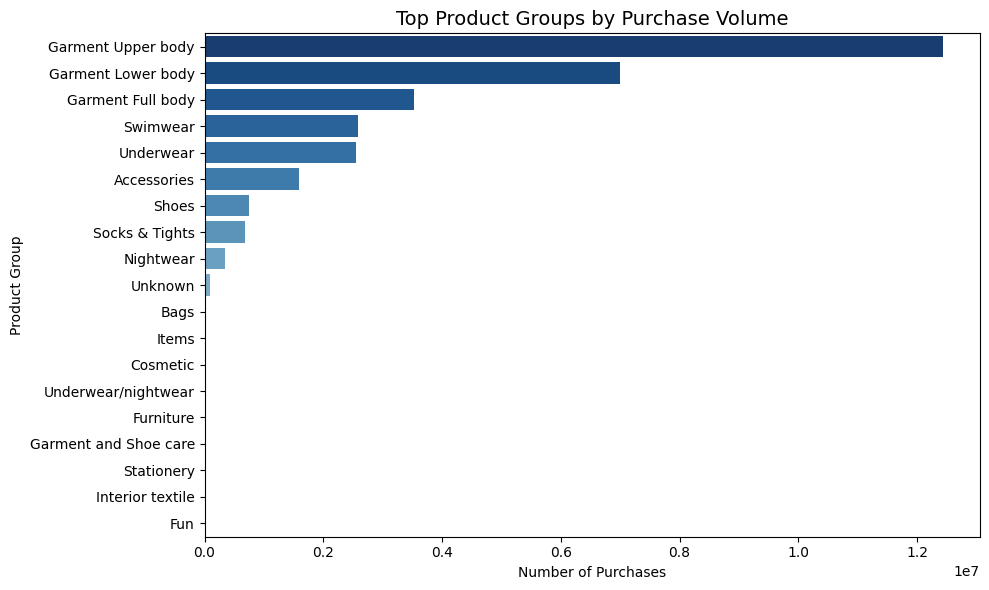

In [ ]:
article_to_group = train_articles.set_index('article_id')['product_group_name'].to_dict() 
product_groups = (
    train_transactions['article_id']
    .map(article_to_group)
    .value_counts()
    .reset_index(name='count')
)

# Rename the columns of the top_article_counts DataFrame
product_groups.columns = ['product_group_name', 'purchase_count']


product_groups.head(10)

plt.figure(figsize=(10, 6))
sns.barplot(data=product_groups, x='purchase_count', y='product_group_name', palette='Blues_r')
plt.title('Top Product Groups by Purchase Volume', fontsize=14)
plt.xlabel('Number of Purchases')
plt.ylabel('Product Group')
plt.tight_layout()
plt.show()

C:\Users\yeshw\AppData\Local\Temp\ipykernel_28784\3139747805.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


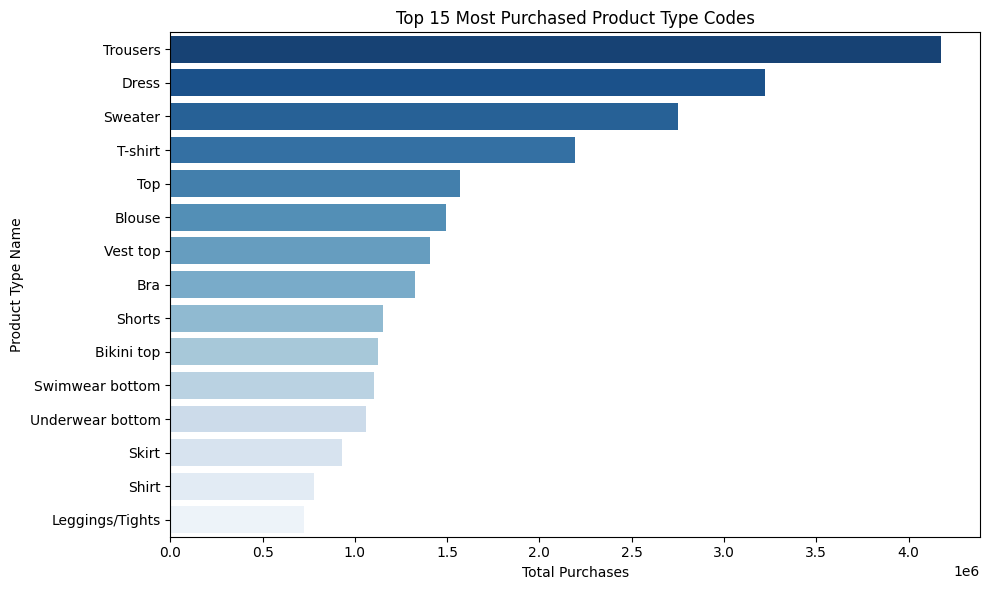

In [44]:
#  lookup dictionary mapping product_type_no -> product_type_name
typeno_to_name = (
    articles_df[['product_type_no', 'product_type_name']]
    .drop_duplicates()
    .set_index('product_type_no')['product_type_name']
    .to_dict()
)

#  Map  cleaned train_articles to get the numeric code from article_id
article_to_typeno_map = train_articles.set_index('article_id')['product_type_no'].to_dict()

#Map onto transactions and get value counts
product_type_counts = (
    train_transactions['article_id']
    .map(article_to_typeno_map)
    .map(typeno_to_name)
    .value_counts()
    .reset_index(name='count')
    .sort_values(by='count', ascending=False)
)

# Take the top 15 most frequent product type numbers 
top_15_types = product_type_counts.head(15)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_15_types, 
    x='count', 
    y='article_id', 
    palette='Blues_r'
)
plt.title('Top 15 Most Purchased Product Type Codes')
plt.xlabel('Total Purchases')
plt.ylabel('Product Type Name')
plt.tight_layout()
plt.show()

In [42]:
top_15_types

,article_id,count
14,Leggings/Tights,725888
13,Shirt,778962
12,Skirt,928682
11,Underwear bottom,1059932
10,Swimwear bottom,1103032
9,Bikini top,1124955
8,Shorts,1151116
7,Bra,1326353
6,Vest top,1408724
5,Blouse,1494212


##### 2) Customer Age Distribution

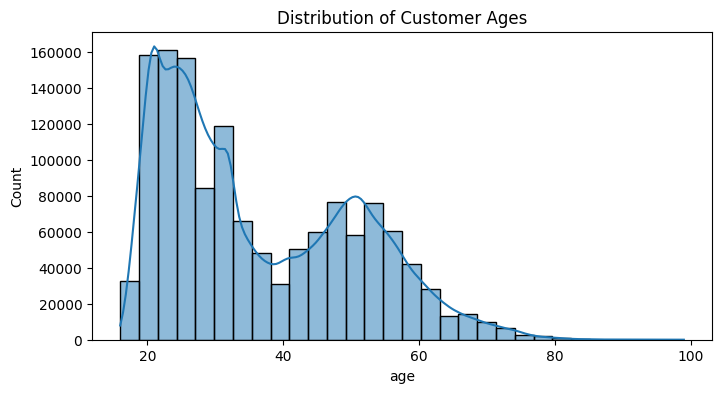

In [18]:
plt.figure(figsize=(8, 4))
sns.histplot(train_customers['age'], bins=30, kde=True)
plt.title('Distribution of Customer Ages')
plt.show()

##### 3) Customer Count per Age Category

age_group
Teens (<21)             190768
Young Adults (21-35)    586259
Adult (36-50)           293792
Mature (51+)            285890
Name: count, dtype: int64


C:\Users\yeshw\AppData\Local\Temp\ipykernel_28784\2541825924.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=age_group_counts.index, y=age_group_counts.values, palette='viridis')


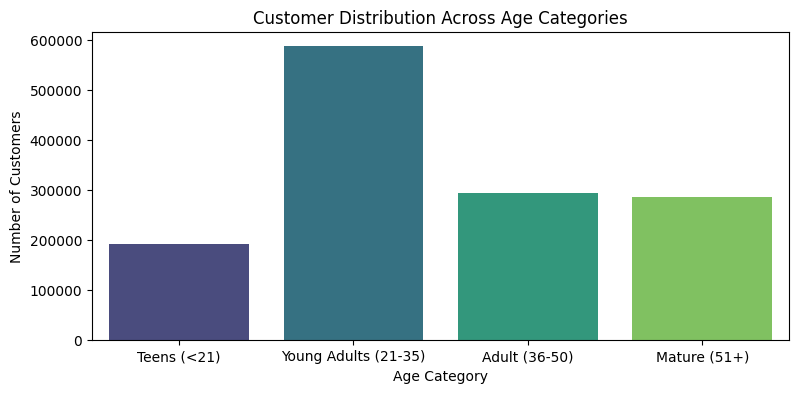

In [19]:
# Age Binning: Create meaningful age categories for analysis
bins = [0, 21, 35, 50, 100]
labels = ['Teens (<21)', 'Young Adults (21-35)', 'Adult (36-50)', 'Mature (51+)']

train_customers_copy = train_customers.copy()
train_customers_copy['age_group'] = pd.cut(
    train_customers_copy['age'], 
    bins=bins, 
    labels=labels
)

# Customer distribution across age groups
age_group_counts = train_customers_copy['age_group'].value_counts().sort_index()
print(age_group_counts)

plt.figure(figsize=(9, 4))
sns.barplot(x=age_group_counts.index, y=age_group_counts.values, palette='viridis')
plt.title('Customer Distribution Across Age Categories')
plt.xlabel('Age Category')
plt.ylabel('Number of Customers')
plt.show()

#### 5) Number of customers in Fashion News Frequency

fashion_news_frequency
NONE         884012
Regularly    471858
Monthly         839
Name: count, dtype: int64


C:\Users\yeshw\AppData\Local\Temp\ipykernel_28784\3084429064.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  s = sns.barplot(x="Fashion News Frequency", y="Customers", data=df, palette="pastel")


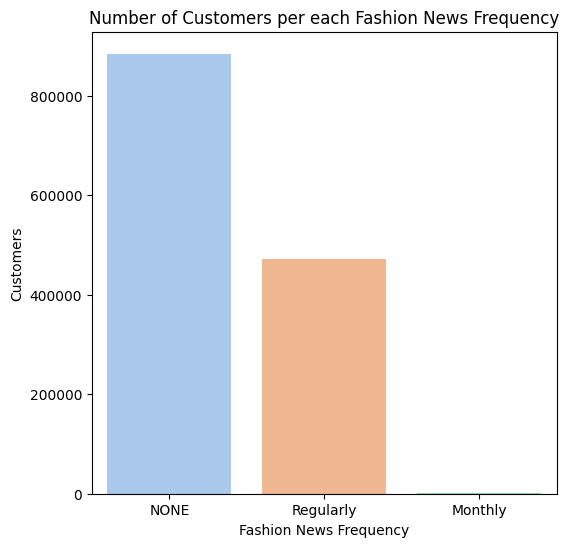

In [ ]:
# # Number of customers in Fashion News Frequency
print(train_customers.fashion_news_frequency.value_counts())
temp = train_customers.groupby(["fashion_news_frequency"])["customer_id"].count()
df = pd.DataFrame({"Fashion News Frequency": temp.index, "Customers": temp.values})
df = df.sort_values(["Customers"], ascending=False)
plt.figure(figsize=(6, 6))
plt.title(f"Number of Customers per each Fashion News Frequency")
sns.set_color_codes("pastel")
s = sns.barplot(x="Fashion News Frequency", y="Customers", data=df, palette="pastel")
locs, labels = plt.xticks()
plt.show()

##### 4) Product Group Preferences Across  Age Category

In [21]:
merged_age_pdtGrp = train_transactions.merge(
    train_customers_copy[['customer_id', 'age_group']], 
    on='customer_id', 
    how='inner'
).merge(
    train_articles[['article_id', 'product_group_name']], 
    on='article_id', 
    how='inner'
)

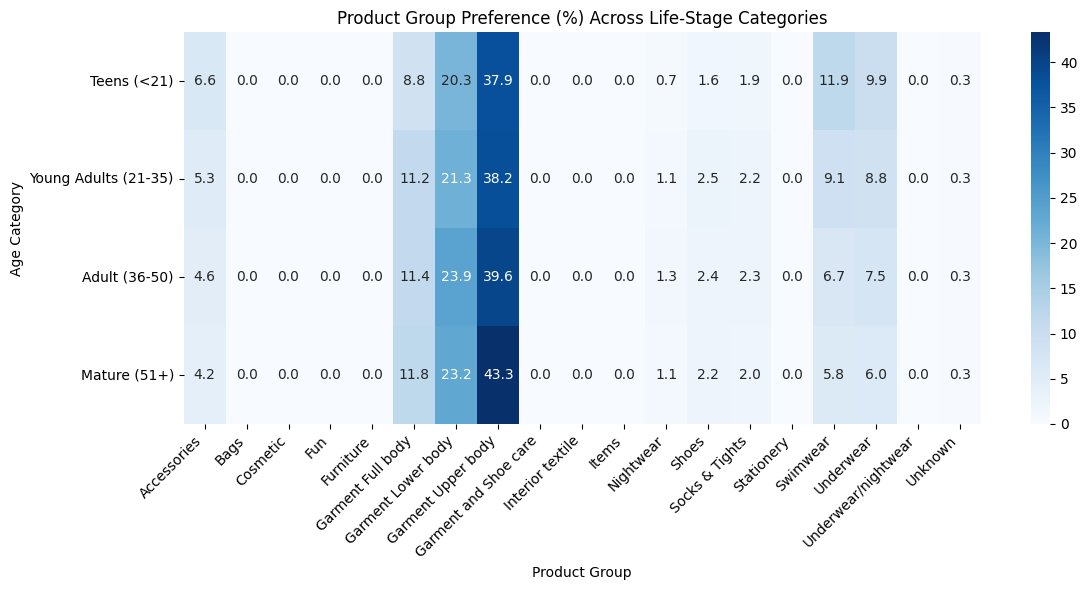

In [23]:
# Create a normalized cross-tabulation (percentage breakdown per age group)
age_pref = pd.crosstab(merged_age_pdtGrp['age_group'], merged_age_pdtGrp['product_group_name'], normalize='index') * 100

# Plot Heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(age_pref, annot=True, fmt='.1f', cmap='Blues', cbar=True)
plt.title('Product Group Preference (%) Across Life-Stage Categories')
plt.xlabel('Product Group')
plt.ylabel('Age Category')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Inference:** Across every single age bracket (Teens to Mature), the dominant categories are identical

#### 5) Monthly Transactions Trend

     t_dat  transaction_count
0  2018-09             594776
1  2018-10            1397040
2  2018-11            1270619
3  2018-12            1148827
4  2019-01            1263471


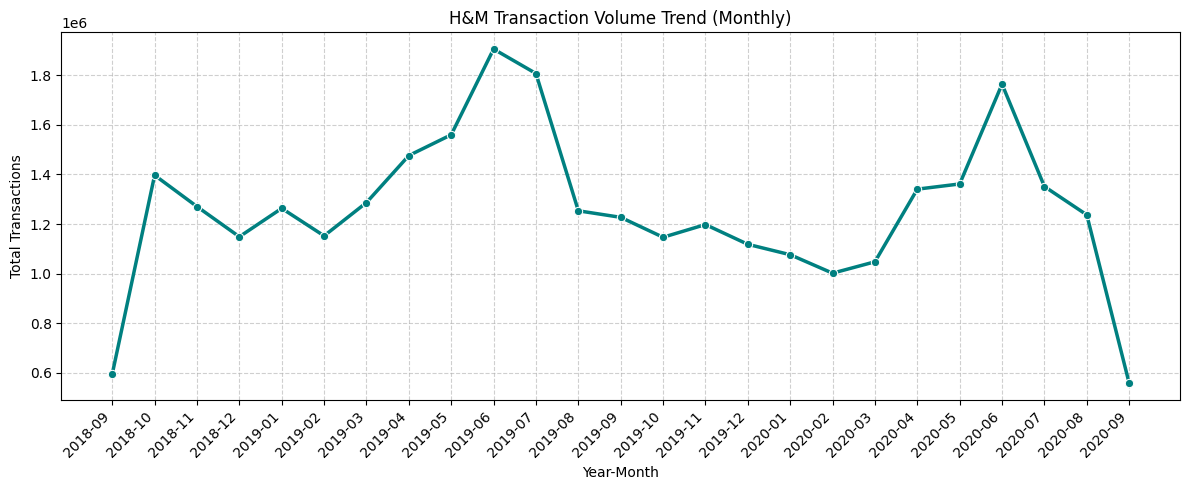

In [ ]:
monthly_trend = (
    train_transactions
    .groupby(train_transactions['t_dat'].dt.to_period('M'))
    .size()
    .reset_index(name='transaction_count')
)

# Convert Period back to string/timestamp for clean plotting
monthly_trend['t_dat'] = monthly_trend['t_dat'].astype(str)

print(monthly_trend.head())

# 3. Plot Monthly Trend
plt.figure(figsize=(12, 5))
sns.lineplot(
    data=monthly_trend, 
    x='t_dat', 
    y='transaction_count', 
    marker='o', 
    color='teal', 
    linewidth=2.5
)
plt.title('H&M Transaction Volume Trend (Monthly)')
plt.xlabel('Year-Month')
plt.ylabel('Total Transactions')
plt.xticks(rotation=45, ha='right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()